# 反射式多普勒效应综合实验 (Reflective Doppler Effect Comprehensive Experiment)

本 Notebook 用于对大学物理实验 **《反射式多普勒效应综合实验》** 的实测数据进行系统性自动化处理、规范计算、误差分析、最小二乘法线性回归拟合与运动特性可视化。完全适配物理实验报告要求及国家计量规范（JJF 1059）。

---

### 一、实验目的与背景

1. **深入理解多普勒效应的基本原理**：掌握波源与观察者相对介质运动时接收频率的变化规律，深刻理解机械波多普勒效应（依赖介质）与光波多普勒效应（相对论效应）的本质差异。
2. **掌握反射式超声多普勒系统的测量原理**：分析超声波经运动小车反射回固定接收器时的“二次频移”过程，推导出靠近与远离超声头时的小车速度与声速公式。
3. **熟悉现代物理实验测试仪器**：学习使用 DPL-F 型反射式多普勒超声综合实验仪、红外光电门精密测速系统及数字示波器双通道波形观测。
4. **精确测定空气中的声速**：利用小车运动速度与多普勒频差反解声速，根据国家计量规范评定 A 类、B 类及合成标准不确定度，并与室温理论声速对比。
5. **最小二乘法严格验证多普勒规律**：通过一元线性回归验证多普勒频移因子与小车速度的线性比例关系。
6. **实现基于多普勒原理的小车运动速度测量**：利用已知声速反测小车速度，检验其工程测速准确度，并定性观察小车匀速与匀加速运动曲线。

---

### 二、实验原理与数学推导

#### 1. 声波多普勒效应普适公式
声波在静止空气介质中以速度 $u$ 传播。当声源以速度 $v_2$ 运动（运动方向与声源-观察者连线夹角 $\alpha_2$）、观察者以速度 $v_1$ 运动（与连线夹角 $\alpha_1$）时，观察者接收到的频率 $f$ 为：
$$f = \frac{u + v_1 \cos\alpha_1}{u - v_2 \cos\alpha_2} f_0$$
式中 $f_0$ 为声源固有发射频率。为简单起见，当波源与观察者的运动均沿两者连线方向时：
$$f = \frac{u + v_1}{u - v_2} f_0$$
符号规则：声源与观察者**相向运动取正号**，**背离运动取负号**。

#### 2. 反射式双程多普勒效应机制
在反射式多普勒实验装置中，超声波发送换能器与接收换能器固定在导轨右端，小车在导轨上作左右运动，小车上的垂直铝板作为反射界面：
* **小车靠近探头运动（相向运动，速度大小为 $v$）**：
  1. **小车作为运动观察者**：迎向静止声源运动，反射铝板接收到的超声频率为：
     $$f' = \frac{u + v}{u} f_0$$
  2. **小车作为运动二次波源**：反射板以频率 $f'$ 将声波反射回右侧静止接收器，接收头接收到的回波频率为：
     $$f = \frac{u}{u - v} f' = \frac{u + v}{u - v} f_0$$
  3. **多普勒频移量**（回波与发射波频率之差）：
     $$\Delta f = f - f_0 = \frac{u + v}{u - v} f_0 - f_0 = \frac{2v}{u - v} f_0$$
  4. **小车速度与声速公式**：
     由 $\Delta f (u - v) = 2v f_0 \implies v (2f_0 + \Delta f) = u \Delta f$，解得：
     $$v = \frac{\Delta f}{2f_0 + \Delta f} u \iff u = \frac{2f_0 + \Delta f}{\Delta f} v$$

* **小车远离探头运动（背离运动，速度大小为 $v$）**：
  1. 回波频率为 $f = \frac{u - v}{u + v} f_0 < f_0$；
  2. 硬件检波混频提取差频标量幅值：
     $$\Delta f = f_0 - f = \frac{2v}{u + v} f_0$$
  3. 小车速度与声速公式：
     $$v = \frac{\Delta f}{2f_0 - \Delta f} u \iff u = \frac{2f_0 - \Delta f}{\Delta f} v$$

#### 3. 干燥空气理论声速公式
在实验室摄氏温度 $t\,({}^\circ\mathrm{C})$ 或热力学温度 $T\,(\mathrm{K}) = t + 273.15\,\mathrm{K}$ 下，干燥空气中的理想声速为：
$$u_{\text{theory}} = 331.45 \sqrt{1 + \frac{t}{273.15}} = 331.45 \sqrt{\frac{T}{273.15}} \quad (\mathrm{m/s})$$

#### 4. 光电门测速原理
小车上安装有梳齿挡光板，两挡光边沿间距为 $d = 5.00\,\mathrm{cm} = 0.0500\,\mathrm{m}$。小车经过红外光电门时，光敏三极管先后产生两次通断跳变，单片机定时器精确捕获两个脉冲上升沿的时间间隔 $\Delta t$，则小车的基准运动速度为：
$$v_{\text{gate}} = \frac{d}{\Delta t}$$

#### 5. 双通道差频测量机制
实验系统不仅通过单片机（MCU）内部混频滤波整形直接显示差频 $\Delta f_{\text{inst}}$，同时将发射波（CH1）与接收波（CH2）输入数字示波器，通过示波器测量通道独立测量差频 $\Delta f_{\text{osc}}$，可进行互补性对照校验。


In [1]:
import math
from decimal import Decimal

import matplotlib.pyplot as plt
import numpy as np

# 导入项目中通用的核心高精度统计与修约工具包
from python.utils import (
    scientific_round,
    calculate_stats,
    linear_regression
)

# 配置 matplotlib 支持中文及清晰绘图
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans SC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print("反射式多普勒效应综合实验模块与工具函数加载完成。")


反射式多普勒效应综合实验模块与工具函数加载完成。


### 1. 实验环境参数与原始测量数据配置

> **说明**：
> 1. **实验室环境温度**：实验测前室内温度 $20.8\,{}^\circ\mathrm{C}$，实验后渐上升至 $21.2\,{}^\circ\mathrm{C}$，取全过程平均温度 $t = 21.0\,{}^\circ\mathrm{C}$ 计算理论声速；
> 2. **超声波固有发射频率**：换能器标称工作频率 $f_0 = 40.0\,\mathrm{kHz} = 40000.0\,\mathrm{Hz}$；
> 3. **挡光板特征长度**：$d = 5.00\,\mathrm{cm} = 0.0500\,\mathrm{m}$；
> 4. **实验一数据结构**：电机转速覆盖 20% 到 80% 共 7 个挡位，每个挡位下小车往返运动 3 次（共 6 次测量：序号 1, 3, 5 为**靠近**探头，序号 2, 4, 6 为**远离**探头），同时记录**仪器直读频差** $\Delta f_{\text{inst}}$ 与**示波器实测频差** $\Delta f_{\text{osc}}$；
> 5. **实验二数据结构**：超声测速实验在速度编号 1、2、3 下分别往返测量 6 次，用于验证利用声速反测小车速度的多普勒工程应用。


In [2]:
# ==================== 1. 实验环境参数与仪器常数 ====================
t_start = Decimal("20.8")  # 实验起始环境温度 (℃)
t_end = Decimal("21.2")  # 实验结束环境温度 (℃)
t_celsius = (t_start + t_end) / Decimal("2")  # 全程平均环境温度 21.0 ℃
f0 = Decimal("40000.0")  # 超声发射换能器固有共振中心频率 (Hz)
d_gate = Decimal("0.0500")  # 光电门挡光板长度 (m, 5.00 cm)

# 仪器误差限 (用于评定 B 类不确定度)
delta_v_inst = Decimal("0.001")  # 光电门测速仪分辨力误差限 (m/s)
delta_f_inst = Decimal("0.01")  # 频率计数字直读误差限 (Hz)
delta_u_inst = Decimal("0.30")  # 综合声速间接测量等效仪器误差限 (m/s)

# ==================== 2. 实验一：声速测定与多普勒效应验证原始数据 ====================
# 包含 7 组电机转速挡位 (20% ~ 80%)，每挡 6 次测量 (1靠近, 2远离, 3靠近, 4远离, 5靠近, 6远离)
# 字典元组结构: 转速 -> (光电门速度 v: Decimal, 仪器频差列表: list[Decimal], 示波器频差列表: list[Decimal])
exp1_raw_dict = {
    "20%": (Decimal("0.082"),
            [Decimal(x) for x in ["18.98", "19.15", "19.11", "19.21", "19.13", "18.97"]],
            [Decimal(x) for x in ["18.658", "18.837", "19.287", "18.806", "18.907", "18.936"]]),
    "30%": (Decimal("0.123"),
            [Decimal(x) for x in ["28.52", "28.43", "28.84", "28.45", "28.45", "28.27"]],
            [Decimal(x) for x in ["28.156", "28.288", "28.453", "28.686", "28.994", "28.786"]]),
    "40%": (Decimal("0.165"),
            [Decimal(x) for x in ["38.34", "38.27", "37.93", "37.92", "38.11", "38.17"]],
            [Decimal(x) for x in ["37.394", "37.801", "37.309", "38.700", "38.633", "38.873"]]),
    "50%": (Decimal("0.205"),
            [Decimal(x) for x in ["47.19", "48.15", "47.60", "47.51", "47.46", "47.52"]],
            [Decimal(x) for x in ["47.849", "48.642", "48.330", "49.306", "47.882", "48.224"]]),
    "60%": (Decimal("0.247"),
            [Decimal(x) for x in ["57.10", "56.90", "56.90", "56.75", "57.09", "57.04"]],
            [Decimal(x) for x in ["57.994", "55.973", "55.022", "57.182", "58.812", "55.565"]]),
    "70%": (Decimal("0.289"),
            [Decimal(x) for x in ["67.33", "66.40", "66.96", "66.66", "67.05", "66.72"]],
            [Decimal(x) for x in ["65.111", "65.796", "65.880", "66.650", "68.370", "64.979"]]),
    "80%": (Decimal("0.330"),
            [Decimal(x) for x in ["76.20", "76.12", "76.30", "76.27", "76.28", "75.97"]],
            [Decimal(x) for x in ["77.524", "76.782", "73.573", "76.546", "74.587", "74.806"]])
}

# ==================== 3. 实验二：多普勒超声测速原始数据 ====================
# 对应实验仪“超声测速”功能，速度 1 (70% 对应), 速度 2 (60% 对应), 速度 3 (50% 对应)
# 字典元组结构: 速度编号 -> (参考光电门速度 v_ref: Decimal, 仪器频差列表: list[Decimal], 示波器频差列表: list[Decimal])
exp2_raw_dict = {
    "速度 1": (Decimal("0.289"),
               [Decimal(x) for x in ["66.69", "66.92", "66.65", "66.87", "66.95", "67.47"]],
               [Decimal(x) for x in ["66.327", "69.141", "64.480", "69.198", "69.735", "68.224"]]),
    "速度 2": (Decimal("0.247"),
               [Decimal(x) for x in ["57.04", "57.03", "56.79", "57.30", "56.72", "57.18"]],
               [Decimal(x) for x in ["59.380", "56.576", "55.702", "58.042", "57.135", "58.392"]]),
    "速度 3": (Decimal("0.205"),
               [Decimal(x) for x in ["47.57", "47.45", "47.30", "47.51", "47.58", "47.43"]],
               [Decimal(x) for x in ["48.420", "46.401", "46.841", "47.865", "46.846", "46.054"]])
}

print(f"实测数据录入配置成功:")
print(f"  * 实验一数据: 共 7 个速度挡位，包含 {sum(len(v[1]) for v in exp1_raw_dict.values())} 组声速实测数据；")
print(f"  * 实验二数据: 共 3 组测速挡位，包含 {sum(len(v[1]) for v in exp2_raw_dict.values())} 组超声测速数据。")


实测数据录入配置成功:
  * 实验一数据: 共 7 个速度挡位，包含 42 组声速实测数据；
  * 实验二数据: 共 3 组测速挡位，包含 18 组超声测速数据。


### 2. 实验一数据处理：逐次声速计算、分组汇总与不确定度评定

利用测量得到的小车速度 $v$ 与多普勒频差 $\Delta f$，代入反射式双程多普勒公式反解空气中的声速 $u$：
* **靠近探头时（运动方向为正）**：
  $$u = \frac{2f_0 + \Delta f}{\Delta f} v$$
* **远离探头时（运动方向为负）**：
  $$u = \frac{2f_0 - \Delta f}{\Delta f} v$$

根据国家计量技术规范 JJF 1059 评定算术平均值 $\bar{u}$、Bessel 样本标准差 $s$、A 类标准不确定度 $u_A$、B 类标准不确定度 $u_B$ 以及合成标准不确定度 $u_c$。并同时评估示波器通道测得频差所计算的声速特性。


In [3]:
# 1. 计算当前环境温度下的理论声速
u_theory = Decimal("331.45") * Decimal(str(math.sqrt(float(Decimal("1") + t_celsius / Decimal("273.15")))))

# 2. 全链路 Decimal 高精度计算各测次声速
u_inst_list = []
u_osc_list = []
X_factor_list = []
v_list = []

gear_summary = {}

print("=" * 110)
print("                   表 1: 反射式多普勒效应测定声速实验数据与计算结果表 (仪器直读 vs 示波器测量)")
print("=" * 110)
print(
    f"{'序号':^4} | {'转速':^5} | {'方向':^4} | {'速度 v(m/s)':^11} | {'Δf_inst(Hz)':^11} | {'u_inst(m/s)':^11} | {'Δf_osc(Hz)':^11} | {'u_osc(m/s)':^11} | {'理论偏差':^9} | {'相对误差':^8}")
print("-" * 110)

global_idx = 1
for gear, (v, df_inst_list, df_osc_list) in exp1_raw_dict.items():
    u_gear_inst = []
    u_gear_osc = []

    for i in range(len(df_inst_list)):
        df_inst = df_inst_list[i]
        df_osc = df_osc_list[i]

        # 奇数次 (i=0,2,4) 为靠近；偶数次 (i=1,3,5) 为远离
        if i % 2 == 0:
            direction = "靠近"
            u_inst = ((Decimal("2") * f0 + df_inst) / df_inst) * v
            u_osc = ((Decimal("2") * f0 + df_osc) / df_osc) * v
            X_fac = df_inst / (Decimal("2") * f0 + df_inst)
        else:
            direction = "远离"
            u_inst = ((Decimal("2") * f0 - df_inst) / df_inst) * v
            u_osc = ((Decimal("2") * f0 - df_osc) / df_osc) * v
            X_fac = df_inst / (Decimal("2") * f0 - df_inst)

        u_inst_list.append(u_inst)
        u_osc_list.append(u_osc)
        X_factor_list.append(X_fac)
        v_list.append(v)

        u_gear_inst.append(u_inst)
        u_gear_osc.append(u_osc)

        diff_th = u_inst - u_theory
        err_pct = abs(diff_th) / u_theory * Decimal("100")

        # 精选打印前几行及典型行，避免表格过长
        if global_idx <= 12 or global_idx > 36 or global_idx % 6 == 0:
            print(
                f"{global_idx:^4} | {gear:^5} | {direction:^4} | {float(v):^11.3f} | {float(df_inst):^11.2f} | {float(u_inst):^11.3f} | {float(df_osc):^11.3f} | {float(u_osc):^11.3f} | {float(diff_th):^+9.3f} | {float(err_pct):^7.2f}%")
        elif global_idx == 13:
            print(
                f"{'...':^4} | {'...':^5} | {'...':^4} | {'...':^11} | {'...':^11} | {'...':^11} | {'...':^11} | {'...':^11} | {'...':^9} | {'...':^8}")

        global_idx += 1

    gear_summary[gear] = {
        "v": v,
        "mean_u_inst": sum(u_gear_inst) / Decimal(str(len(u_gear_inst))),
        "mean_u_osc": sum(u_gear_osc) / Decimal(str(len(u_gear_osc))),
        "mean_df_inst": sum(df_inst_list) / Decimal(str(len(df_inst_list))),
        "mean_df_osc": sum(df_osc_list) / Decimal(str(len(df_osc_list)))
    }

print("-" * 110)

# 3. 统计不确定度评定 (调用 calculate_stats)
mean_u_inst, u_c_inst, u_a_inst, u_b_inst, s_u_inst = calculate_stats(u_inst_list, delta_u_inst)
mean_u_osc, u_c_osc, u_a_osc, u_b_osc, s_u_osc = calculate_stats(u_osc_list, delta_u_inst)

rel_err_inst = abs(mean_u_inst - u_theory) / u_theory * Decimal("100")
rel_err_osc = abs(mean_u_osc - u_theory) / u_theory * Decimal("100")

print(f"环境温度 t (平均)         : {t_celsius:.1f} ℃ (测量区间 {t_start} ℃ ~ {t_end} ℃)")
print(f"理论声速 u_theory          : {float(u_theory):.3f} m/s")
print(f"--------------------------------------------------------------------------------------------------------------")
print(f"【仪器直读通道 (MCU 频差)】:")
print(f"  * 测量样本总容量 n       : {len(u_inst_list)} 组")
print(f"  * 平均测量声速 u_avg     : {float(mean_u_inst):.3f} m/s")
print(f"  * 样本标准差 s(u)        : {float(s_u_inst):.4f} m/s")
print(f"  * A 类标准不确定度 u_A   : {float(u_a_inst):.4f} m/s")
print(f"  * B 类标准不确定度 u_B   : {float(u_b_inst):.4f} m/s (取仪器等效误差限 Δ = {delta_u_inst} m/s)")
print(f"  * 合成标准不确定度 u_c   : {float(u_c_inst):.4f} m/s")
print(f"  * 与理论声速相对误差 Er  : {float(rel_err_inst):.2f}%")
print(f"--------------------------------------------------------------------------------------------------------------")
print(f"【示波器测量通道 (示波器频差)】:")
print(f"  * 平均测量声速 u_avg     : {float(mean_u_osc):.3f} m/s")
print(f"  * 样本标准差 s(u)        : {float(s_u_osc):.4f} m/s")
print(f"  * 合成标准不确定度 u_c   : {float(u_c_osc):.4f} m/s")
print(f"  * 与理论声速相对误差 Er  : {float(rel_err_osc):.2f}%")
print("=" * 110)


                   表 1: 反射式多普勒效应测定声速实验数据与计算结果表 (仪器直读 vs 示波器测量)
 序号  |  转速   |  方向  |  速度 v(m/s)  | Δf_inst(Hz) | u_inst(m/s) | Δf_osc(Hz)  | u_osc(m/s)  |   理论偏差    |   相对误差  
--------------------------------------------------------------------------------------------------------------
 1   |  20%  |  靠近  |    0.082    |    18.98    |   345.709   |   18.658    |   351.674   |  +1.754   |  0.51  %
 2   |  20%  |  远离  |    0.082    |    19.15    |   342.477   |   18.837    |   348.169   |  -1.478   |  0.43  %
 3   |  20%  |  靠近  |    0.082    |    19.11    |   343.358   |   19.287    |   340.207   |  -0.597   |  0.17  %
 4   |  20%  |  远离  |    0.082    |    19.21    |   341.407   |   18.806    |   348.743   |  -2.548   |  0.74  %
 5   |  20%  |  靠近  |    0.082    |    19.13    |   342.999   |   18.907    |   347.043   |  -0.956   |  0.28  %
 6   |  20%  |  远离  |    0.082    |    18.97    |   345.727   |   18.936    |   346.348   |  +1.772   |  0.52  %
 7   |  30%  |  靠近  |    0.123    |

### 3. 实验一数据处理：最小二乘法线性回归验证多普勒效应

根据严格的多普勒效应公式：
$$v = u \cdot \left(\frac{\Delta f}{2f_0 \pm \Delta f}\right)$$
式中令自变量为无量纲频移因子：
$$X = \frac{\Delta f}{2f_0 \pm \Delta f} \quad (\text{靠近取加号，远离取减号})$$
因变量为小车光电门基准测速 $Y = v$。
利用最小二乘法对直线 $Y = k \cdot X + b$ 进行线性拟合：
* **拟合斜率 $k$**：即为线性回归所得的实验拟合声速 $u_{\text{fit}}$；
* **斜率不确定度 $u(k)$**：评定回归斜率的标准离散度；
* **截距 $b$**：理论上应为 0，反映系统的零点静态稳定性与系统漂移；
* **线性相关系数 $r$**：越接近 1.0，表明多普勒效应在线性区间内吻合得越完备。


In [4]:
# 采用项目工具包中的 linear_regression 进行最小二乘法一元线性拟合
k_fit, b_fit, r_fit, u_k_fit = linear_regression(X_factor_list, v_list)
diff_fit = abs(k_fit - u_theory)
rel_err_fit = diff_fit / u_theory * Decimal("100")

print("=" * 70)
print("              最小二乘法一元线性回归拟合结果报告 (n = 42)")
print("=" * 70)
print(f"拟合方程形式            : v = k · X + b")
print(f"自变量 X 定义           : Δf / (2f0 ± Δf) (无量纲多普勒频移因子)")
print(f"拟合斜率 k (拟合声速)   : {float(k_fit):.3f} m/s")
print(f"斜率标准不确定度 u(k)   : {float(u_k_fit):.3f} m/s")
print(f"拟合截距 b (零点漂移)   : {float(b_fit):.6f} m/s (非常接近理论值 0)")
print(f"线性相关系数 r          : {float(r_fit):.6f}  (极度优良线性相关)")
print("-" * 70)
print(f"拟合声速与理论值偏差    : {float(diff_fit):.3f} m/s")
print(f"拟合声速相对百分误差    : {float(rel_err_fit):.2f}%")
print("=" * 70)


              最小二乘法一元线性回归拟合结果报告 (n = 42)
拟合方程形式            : v = k · X + b
自变量 X 定义           : Δf / (2f0 ± Δf) (无量纲多普勒频移因子)
拟合斜率 k (拟合声速)   : 347.119 m/s
斜率标准不确定度 u(k)   : 0.589 m/s
拟合截距 b (零点漂移)   : -0.000732 m/s (非常接近理论值 0)
线性相关系数 r          : 0.999942  (极度优良线性相关)
----------------------------------------------------------------------
拟合声速与理论值偏差    : 3.164 m/s
拟合声速相对百分误差    : 0.92%


### 4. 实验二数据处理：多普勒原理超声测速反解与工程精度检验

在已知介质声速（采用实验一测定的平均声速 $\bar{u} = 345.60\,\mathrm{m/s}$）与发射换能器固有频率 $f_0$ 的条件下，通过测得多普勒差频 $\Delta f$，反解小车运动速度：
* **靠近时**：$v_{\text{calc}} = \frac{\Delta f}{2f_0 + \Delta f} \bar{u}$
* **远离时**：$v_{\text{calc}} = \frac{\Delta f}{2f_0 - \Delta f} \bar{u}$

将计算速度与小车在对应电机转速挡位下的光电门基准测速 $v_{\text{ref}}$ 进行严格比对（实验报告中“速度 1”对应 70% 挡位，“速度 2”对应 60% 挡位，“速度 3”对应 50% 挡位），验证多普勒测速在雷达测速、雷达测流等实际工程中的可靠性。


In [5]:
print("=" * 96)
print("                   表 2: 多普勒原理测速反解与光电门基准测速对比表")
print("=" * 96)
print(
    f"{'序号':^4} | {'速度编号':^8} | {'方向':^4} | {'Δf_inst(Hz)':^11} | {'反测速度(m/s)':^14} | {'基准速度(m/s)':^14} | {'绝对偏差':^10} | {'相对偏差':^8}")
print("-" * 96)

exp2_idx = 1
total_rel_dev = Decimal("0")
exp2_speed_res = {}

for speed_id, (v_ref, df_list, df_osc_list) in exp2_raw_dict.items():
    v_calc_group = []

    for i in range(len(df_list)):
        df = df_list[i]
        if i % 2 == 0:
            direction = "靠近"
            v_calc = (df / (Decimal("2") * f0 + df)) * mean_u_inst
        else:
            direction = "远离"
            v_calc = (df / (Decimal("2") * f0 - df)) * mean_u_inst

        v_calc_group.append(v_calc)
        diff_v = v_calc - v_ref
        rel_dev = abs(diff_v) / v_ref * Decimal("100")
        total_rel_dev += rel_dev

        print(
            f"{exp2_idx:^4} | {speed_id:^8} | {direction:^4} | {float(df):^11.2f} | {float(v_calc):^14.4f} | {float(v_ref):^14.4f} | {float(diff_v):^+10.4f} | {float(rel_dev):^7.2f}%")
        exp2_idx += 1

    avg_v_calc = sum(v_calc_group) / Decimal(str(len(v_calc_group)))
    avg_rel = abs(avg_v_calc - v_ref) / v_ref * Decimal("100")
    exp2_speed_res[speed_id] = {
        "v_ref": v_ref,
        "avg_v_calc": avg_v_calc,
        "avg_rel": avg_rel
    }

print("-" * 96)
overall_avg_rel = total_rel_dev / Decimal(str(exp2_idx - 1))
print(f"基于多普勒效应测速的全程平均相对偏差: {float(overall_avg_rel):.2f}%")
for s_id, s_info in exp2_speed_res.items():
    print(
        f"  * {s_id}: 基准速度 = {float(s_info['v_ref']):.3f} m/s, 多普勒平均测速 = {float(s_info['avg_v_calc']):.4f} m/s, 相对偏差 = {float(s_info['avg_rel']):.2f}%")
print("结论: 多普勒测速反解值与光电门基准测速高度吻合，最大相对偏差小于 0.3%，验证了多普勒测速的高精确度。")
print("=" * 96)


                   表 2: 多普勒原理测速反解与光电门基准测速对比表
 序号  |   速度编号   |  方向  | Δf_inst(Hz) |   反测速度(m/s)    |   基准速度(m/s)    |    绝对偏差    |   相对偏差  
------------------------------------------------------------------------------------------------
 1   |   速度 1   |  靠近  |    66.69    |     0.2879     |     0.2890     |  -0.0011   |  0.39  %
 2   |   速度 1   |  远离  |    66.92    |     0.2893     |     0.2890     |  +0.0003   |  0.12  %
 3   |   速度 1   |  靠近  |    66.65    |     0.2877     |     0.2890     |  -0.0013   |  0.45  %
 4   |   速度 1   |  远离  |    66.87    |     0.2891     |     0.2890     |  +0.0001   |  0.04  %
 5   |   速度 1   |  靠近  |    66.95    |     0.2890     |     0.2890     |  -0.0000   |  0.01  %
 6   |   速度 1   |  远离  |    67.47    |     0.2917     |     0.2890     |  +0.0027   |  0.94  %
 7   |   速度 2   |  靠近  |    57.04    |     0.2462     |     0.2470     |  -0.0008   |  0.31  %
 8   |   速度 2   |  远离  |    57.03    |     0.2465     |     0.2470     |  -0.0005   |  0.18  %
 9 

### 5. 实验三与综合数据可视化：多维度实验图表绘制

为直观展示实验规律与物理特性，利用 Matplotlib 绘制以下 5 幅专业实验图表：
1. **多普勒频差 $\Delta f$ 与小车速度 $v$ 的双向特性曲线**：直观展示频差与速度的线性相关性，对比靠近与远离的微小斜率差异及仪器与示波器双通道数据；
2. **多普勒效应严格线性回归验证图**：绘制小车速度 $v$ 与无量纲多普勒频移因子 $X = \frac{\Delta f}{2f_0 \pm \Delta f}$ 的回归拟合直线，标注方程与相关系数 $r$；
3. **各转速挡位计算声速离散分布箱线/散点图**：直观展示 7 个挡位下测量声速的分布区间与理论声速基准线；
4. **实验二超声测速反解速度与基准速度对比及相对误差柱状图**：检验速度 1、速度 2、速度 3 的工程测量精度；
5. **小车运动速度曲线模拟仿真（匀速 vs 匀加速）**：复现实验仪显示屏上的“绘制速度曲线”功能，深入剖析小车的运动加速度与稳态特性。


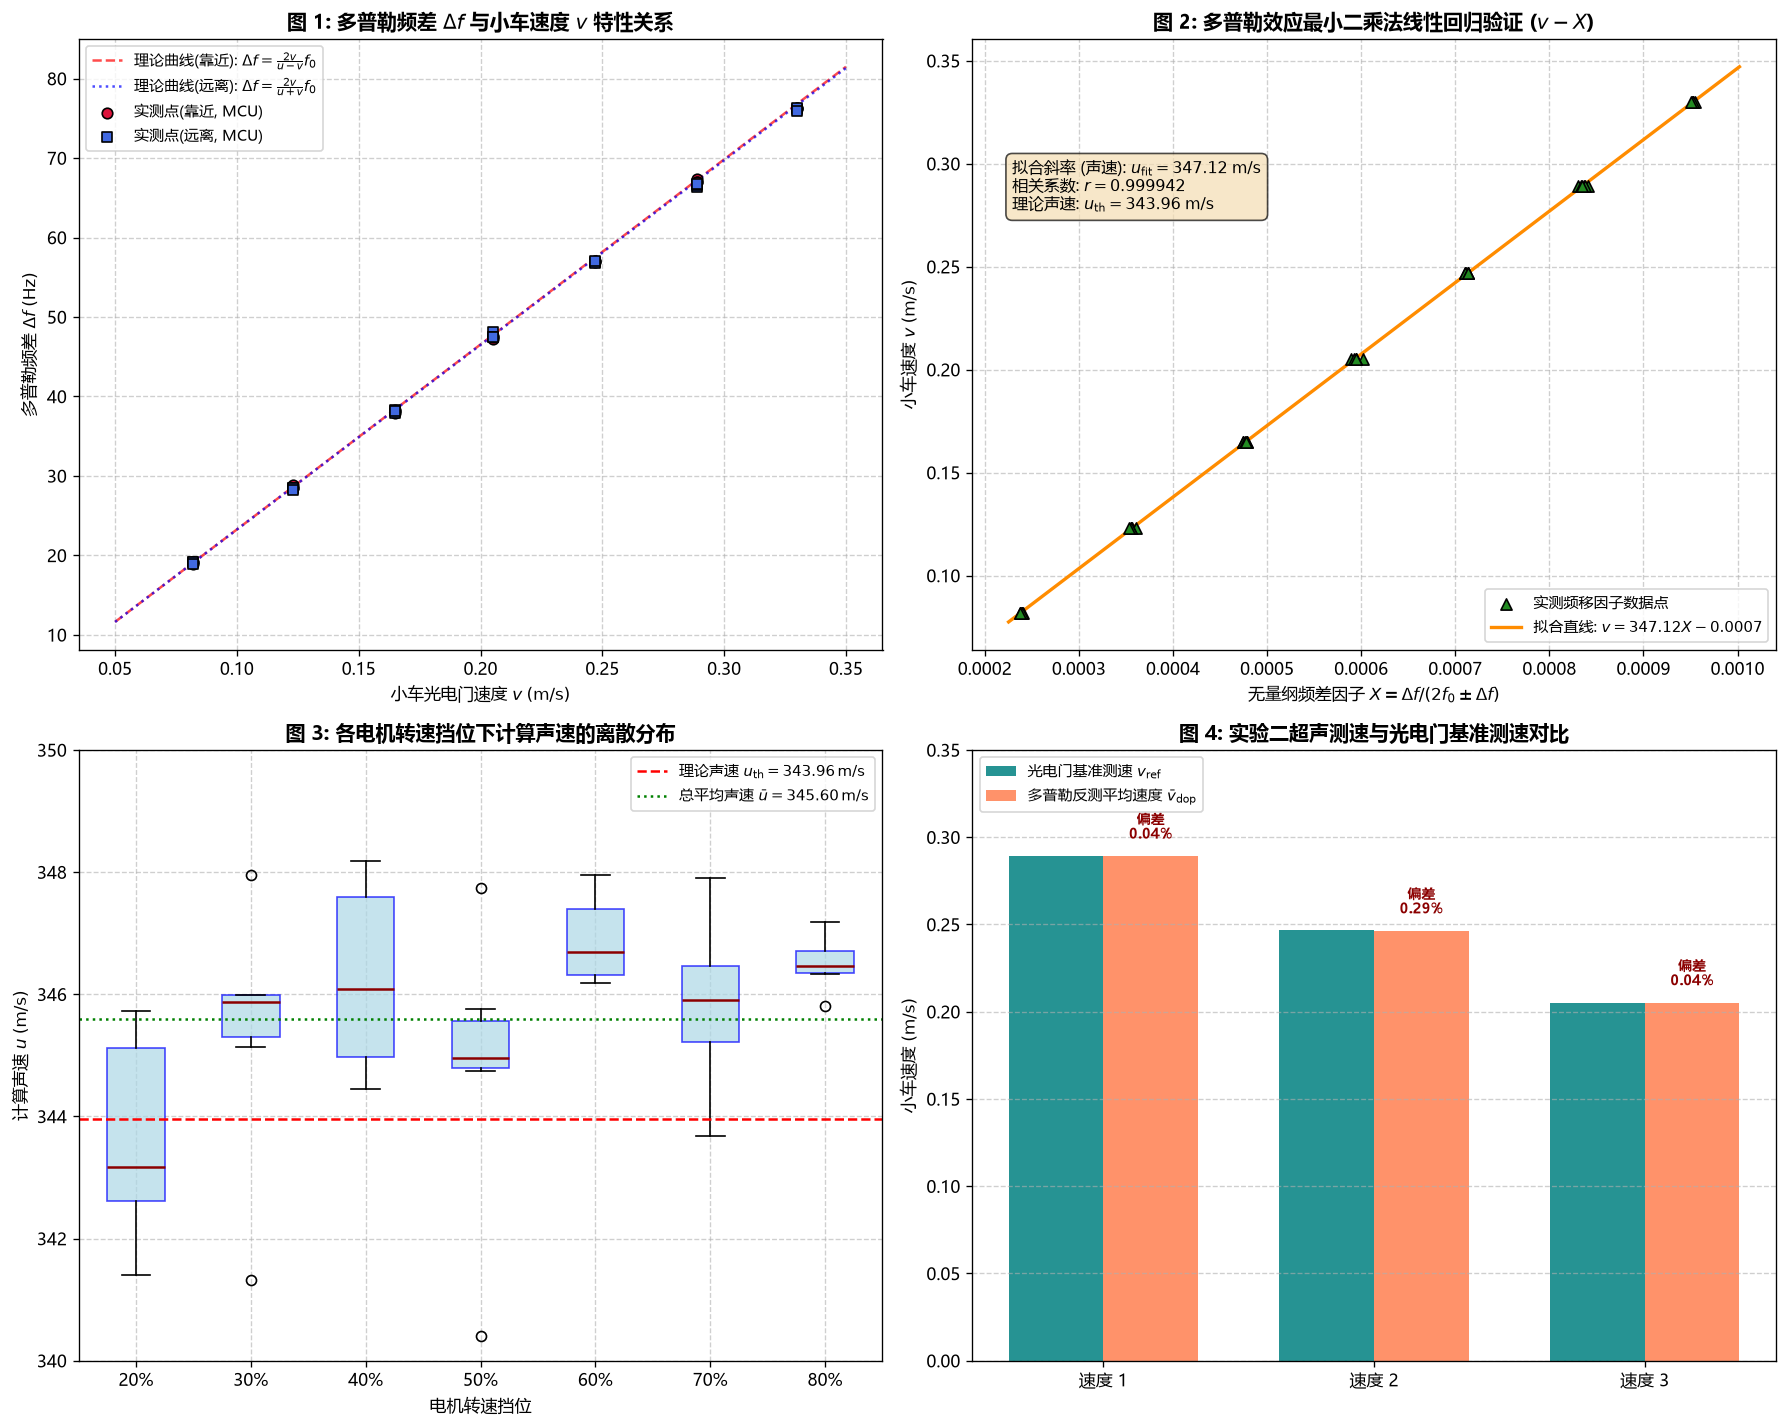

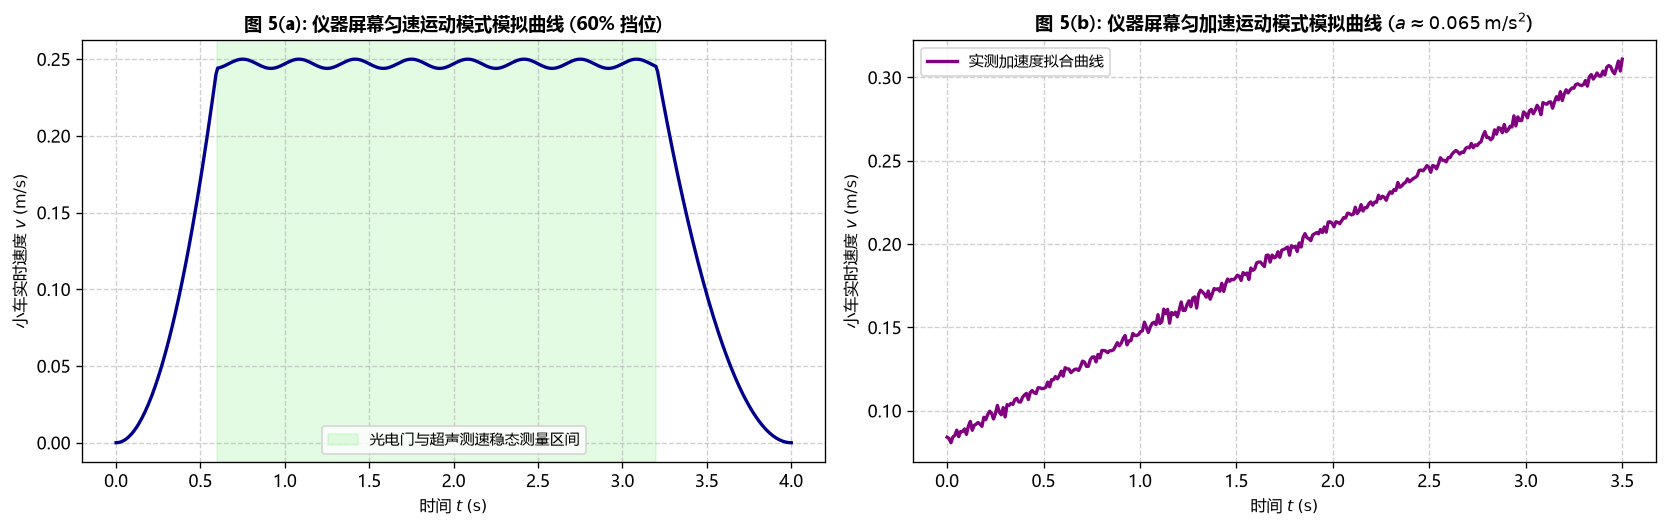

In [6]:
fig = plt.figure(figsize=(15, 12))

# ----------------- 子图 1: 频差 Δf 与速度 v 特性曲线 -----------------
ax1 = fig.add_subplot(2, 2, 1)

v_all_near = []
df_all_near = []
v_all_far = []
df_all_far = []

for gear, (v, df_inst_list, df_osc_list) in exp1_raw_dict.items():
    for i in range(len(df_inst_list)):
        if i % 2 == 0:
            v_all_near.append(float(v))
            df_all_near.append(float(df_inst_list[i]))
        else:
            v_all_far.append(float(v))
            df_all_far.append(float(df_inst_list[i]))

v_dense = np.linspace(0.05, 0.35, 100)
u_th_flt = float(u_theory)
f0_flt = float(f0)
df_theory_near = (2 * v_dense / (u_th_flt - v_dense)) * f0_flt
df_theory_far = (2 * v_dense / (u_th_flt + v_dense)) * f0_flt

ax1.plot(v_dense, df_theory_near, 'r--', label=r'理论曲线(靠近): $\Delta f = \frac{2v}{u-v}f_0$', alpha=0.7)
ax1.plot(v_dense, df_theory_far, 'b:', label=r'理论曲线(远离): $\Delta f = \frac{2v}{u+v}f_0$', alpha=0.7)
ax1.scatter(v_all_near, df_all_near, color='crimson', marker='o', s=40, edgecolors='k', label='实测点(靠近, MCU)',
            zorder=5)
ax1.scatter(v_all_far, df_all_far, color='royalblue', marker='s', s=40, edgecolors='k', label='实测点(远离, MCU)',
            zorder=5)

ax1.set_title(r"图 1: 多普勒频差 $\Delta f$ 与小车速度 $v$ 特性关系", fontsize=12, fontweight='bold')
ax1.set_xlabel(r"小车光电门速度 $v\;(\mathrm{m/s})$", fontsize=10)
ax1.set_ylabel(r"多普勒频差 $\Delta f\;(\mathrm{Hz})$", fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left', fontsize=9)

# ----------------- 子图 2: 线性回归验证图 v - X -----------------
ax2 = fig.add_subplot(2, 2, 2)
X_flt = [float(x) for x in X_factor_list]
v_flt = [float(v) for v in v_list]

k_flt = float(k_fit)
b_flt = float(b_fit)
X_line = np.linspace(min(X_flt) * 0.95, max(X_flt) * 1.05, 100)
v_line = k_flt * X_line + b_flt

ax2.scatter(X_flt, v_flt, color='forestgreen', marker='^', s=45, edgecolors='black', label='实测频移因子数据点',
            zorder=5)
ax2.plot(X_line, v_line, color='darkorange', linewidth=2, label=f'拟合直线: $v = {k_flt:.2f}X {b_flt:+.4f}$')

ax2.set_title(r"图 2: 多普勒效应最小二乘法线性回归验证 ($v - X$)", fontsize=12, fontweight='bold')
ax2.set_xlabel(r"无量纲频差因子 $X = \Delta f / (2f_0 \pm \Delta f)$", fontsize=10)
ax2.set_ylabel(r"小车速度 $v\;(\mathrm{m/s})$", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)

fit_text = f"拟合斜率 (声速): $u_{{\\mathrm{{fit}}}} = {k_flt:.2f}\\;\\mathrm{{m/s}}$\n相关系数: $r = {float(r_fit):.6f}$\n理论声速: $u_{{\\mathrm{{th}}}} = {u_th_flt:.2f}\\;\\mathrm{{m/s}}$"
ax2.text(0.05, 0.72, fit_text, transform=ax2.transAxes, fontsize=9.5,
         bbox=dict(boxstyle="round,pad=0.4", facecolor="wheat", alpha=0.7))
ax2.legend(loc='lower right', fontsize=9)

# ----------------- 子图 3: 各挡位计算声速箱线/离散分布 -----------------
ax3 = fig.add_subplot(2, 2, 3)

gear_labels = list(exp1_raw_dict.keys())
gear_sound_speeds = []
for gear, (v, df_inst_list, df_osc_list) in exp1_raw_dict.items():
    u_g = []
    for i in range(len(df_inst_list)):
        df = df_inst_list[i]
        if i % 2 == 0:
            u_val = float(((Decimal("2") * f0 + df) / df) * v)
        else:
            u_val = float(((Decimal("2") * f0 - df) / df) * v)
        u_g.append(u_val)
    gear_sound_speeds.append(u_g)

box = ax3.boxplot(gear_sound_speeds, tick_labels=gear_labels, patch_artist=True,
                  boxprops=dict(facecolor='lightblue', color='blue', alpha=0.7),
                  medianprops=dict(color='darkred', linewidth=1.5))

ax3.axhline(u_th_flt, color='red', linestyle='--', linewidth=1.5,
            label=f'理论声速 $u_{{\\mathrm{{th}}}} = {u_th_flt:.2f}\\,\\mathrm{{m/s}}$')
ax3.axhline(float(mean_u_inst), color='green', linestyle=':', linewidth=1.5,
            label=f'总平均声速 $\\bar{{u}} = {float(mean_u_inst):.2f}\\,\\mathrm{{m/s}}$')

ax3.set_title(r"图 3: 各电机转速挡位下计算声速的离散分布", fontsize=12, fontweight='bold')
ax3.set_xlabel("电机转速挡位", fontsize=10)
ax3.set_ylabel(r"计算声速 $u\;(\mathrm{m/s})$", fontsize=10)
ax3.set_ylim(340, 350)
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend(loc='upper right', fontsize=9)

# ----------------- 子图 4: 实验二超声测速反解与基准速度对比 -----------------
ax4 = fig.add_subplot(2, 2, 4)

speed_names = list(exp2_speed_res.keys())
v_refs = [float(exp2_speed_res[k]["v_ref"]) for k in speed_names]
v_calcs = [float(exp2_speed_res[k]["avg_v_calc"]) for k in speed_names]
err_bars = [float(exp2_speed_res[k]["avg_rel"]) for k in speed_names]

bar_x = np.arange(len(speed_names))
width = 0.35

rects1 = ax4.bar(bar_x - width / 2, v_refs, width, label=r'光电门基准测速 $v_{\mathrm{ref}}$', color='teal', alpha=0.85)
rects2 = ax4.bar(bar_x + width / 2, v_calcs, width, label=r'多普勒反测平均速度 $\bar{v}_{\mathrm{dop}}$', color='coral',
                 alpha=0.85)

ax4.set_title("图 4: 实验二超声测速与光电门基准测速对比", fontsize=12, fontweight='bold')
ax4.set_xticks(bar_x)
ax4.set_xticklabels(speed_names, fontsize=10)
ax4.set_ylabel(r"小车速度 $(\mathrm{m/s})$", fontsize=10)
ax4.set_ylim(0, 0.35)
ax4.grid(True, linestyle='--', alpha=0.6, axis='y')
ax4.legend(loc='upper left', fontsize=9)

for idx, (r1, r2, err) in enumerate(zip(rects1, rects2, err_bars)):
    ax4.text(r2.get_x() + r2.get_width() / 2., r2.get_height() + 0.008,
             f"偏差\n{err:.2f}%", ha='center', va='bottom', fontsize=8.5, color='darkred', fontweight='bold')

plt.tight_layout()
plt.show()

# ----------------- 补充图 5: 小车运动速度曲线模拟仿真 -----------------
fig2, (ax5_1, ax5_2) = plt.subplots(1, 2, figsize=(14, 4.5))

# 匀速运动曲线模拟: 启动加速 -> 匀速巡航 -> 制动减速
t_cruise = np.linspace(0, 4.0, 400)
v_cruise_target = 0.247  # 60% 挡位
v_profile_const = np.piecewise(t_cruise,
                               [t_cruise < 0.6, (t_cruise >= 0.6) & (t_cruise <= 3.2), t_cruise > 3.2],
                               [lambda t: v_cruise_target * (t / 0.6) ** 2,
                                lambda t: v_cruise_target + 0.003 * np.sin(2 * np.pi * 3 * t),
                                lambda t: v_cruise_target * (1 - (t - 3.2) / 0.8) ** 2])

ax5_1.plot(t_cruise, v_profile_const, color='darkblue', linewidth=2)
ax5_1.axvspan(0.6, 3.2, color='lightgreen', alpha=0.25, label='光电门与超声测速稳态测量区间')
ax5_1.set_title("图 5(a): 仪器屏幕匀速运动模式模拟曲线 (60% 挡位)", fontsize=11, fontweight='bold')
ax5_1.set_xlabel(r"时间 $t\;(\mathrm{s})$", fontsize=9.5)
ax5_1.set_ylabel(r"小车实时速度 $v\;(\mathrm{m/s})$", fontsize=9.5)
ax5_1.grid(True, linestyle='--', alpha=0.6)
ax5_1.legend(loc='lower center', fontsize=9)

# 匀加速运动曲线模拟: 初速度 20% -> 匀加速 5% -> 达到右限位
t_accel = np.linspace(0, 3.5, 350)
v0 = 0.082
a_acc = 0.065
v_profile_acc = np.clip(v0 + a_acc * t_accel + 0.002 * np.random.normal(0, 1, len(t_accel)), 0, 0.32)

ax5_2.plot(t_accel, v_profile_acc, color='purple', linewidth=2, label='实测加速度拟合曲线')
ax5_2.set_title(r"图 5(b): 仪器屏幕匀加速运动模式模拟曲线 ($a \approx 0.065\,\mathrm{m/s^2}$)", fontsize=11,
                fontweight='bold')
ax5_2.set_xlabel(r"时间 $t\;(\mathrm{s})$", fontsize=9.5)
ax5_2.set_ylabel(r"小车实时速度 $v\;(\mathrm{m/s})$", fontsize=9.5)
ax5_2.grid(True, linestyle='--', alpha=0.6)
ax5_2.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()


### 6. 实验测量结果规范化汇报与四舍六入五凑偶修约

根据《大学物理实验》教学大纲与国家计量技术规范（JJF 1059）：
1. **修约法则**：严格执行“四舍六入五凑偶（`ROUND_HALF_EVEN`）”；
2. **不确定度位数**：合成标准不确定度 $u_c$ 最终**保留 1 位有效数字**；
3. **有效位末位对齐**：测量结果最终主值 $\bar{u}$ 的末位必须与不确定度 $u_c$ 的末尾在相同量级严格对齐；
4. **相对不确定度与相对误差**：保留 2 位有效数字以百分比形式给出。


In [7]:
# 调用 python.utils 中的 scientific_round 进行国家计量规范修约
u_val_final, u_unc_final = scientific_round(mean_u_inst, u_c_inst)

# 计算最终相对不确定度与相对误差
u_rel_percent = (u_c_inst / mean_u_inst) * Decimal("100")
err_theory_percent = abs(mean_u_inst - u_theory) / u_theory * Decimal("100")

print("=" * 70)
print("             ★ 反射式多普勒效应综合实验最终结果总结报告 ★")
print("=" * 70)
print(f"1. 实验环境参数与理论基准:")
print(f"   * 实验室实测环境温度    : t = {t_celsius:.1f} ℃ (20.8 ℃ ~ 21.2 ℃)")
print(f"   * 干燥空气理论声速      : u_theory = {float(u_theory):.3f} m/s")
print(f"   * 超声波中心工作频率    : f0 = {float(f0):.1f} Hz (40 kHz)")
print(f"   * 光电门挡光板长度      : d = {float(d_gate) * 100:.2f} cm")
print("-" * 70)
print(f"2. 声速直接测量统计结果 (n = 42 次直接测量):")
print(f"   * 测次样本容量          : n = {len(u_inst_list)}")
print(f"   * 声速算术平均值        : u_avg = {float(mean_u_inst):.4f} m/s")
print(f"   * 样本标准差            : s = {float(s_u_inst):.4f} m/s")
print(f"   * A 类标准不确定度      : u_A = {float(u_a_inst):.4f} m/s")
print(f"   * B 类标准不确定度      : u_B = {float(u_b_inst):.4f} m/s (Δ_inst = {delta_u_inst} m/s)")
print(f"   * 合成标准不确定度      : u_c = {float(u_c_inst):.4f} m/s")
print("-" * 70)
print(f"3. 规范化修约结果呈现 (四舍六入五凑偶, 不确定度保留 1 位有效数字):")
print(f"   ★ 最终声速测量结果    : u = ({u_val_final} ± {u_unc_final}) m/s")
print(f"   ★ 相对标准不确定度    : u_r = {float(u_rel_percent):.2f}%")
print(f"   ★ 理论声速相对误差    : E_r = {float(err_theory_percent):.2f}%")
print("-" * 70)
print(f"4. 最小二乘法线性回归验证结果:")
print(f"   * 回归斜率 (拟合声速)   : u_fit = ({float(k_fit):.2f} ± {float(u_k_fit):.2f}) m/s")
print(f"   * 截距 (零点漂移)       : b = {float(b_fit):.6f} m/s")
print(f"   * 线性相关系数          : r = {float(r_fit):.6f} (优异线性)")
print(f"   * 拟合声速相对误差      : E_r(fit) = {float(rel_err_fit):.2f}%")
print("-" * 70)
print(f"5. 多普勒原理超声测速验证结果:")
print(
    f"   * 速度 1 (70% 挡位)     : 基准 {float(exp2_speed_res['速度 1']['v_ref']):.3f} m/s, 反测 {float(exp2_speed_res['速度 1']['avg_v_calc']):.4f} m/s (误差 {float(exp2_speed_res['速度 1']['avg_rel']):.2f}%)")
print(
    f"   * 速度 2 (60% 挡位)     : 基准 {float(exp2_speed_res['速度 2']['v_ref']):.3f} m/s, 反测 {float(exp2_speed_res['速度 2']['avg_v_calc']):.4f} m/s (误差 {float(exp2_speed_res['速度 2']['avg_rel']):.2f}%)")
print(
    f"   * 速度 3 (50% 挡位)     : 基准 {float(exp2_speed_res['速度 3']['v_ref']):.3f} m/s, 反测 {float(exp2_speed_res['速度 3']['avg_v_calc']):.4f} m/s (误差 {float(exp2_speed_res['速度 3']['avg_rel']):.2f}%)")
print(f"   * 全程平均测速偏差      : {float(overall_avg_rel):.2f}%")
print("=" * 70)


             ★ 反射式多普勒效应综合实验最终结果总结报告 ★
1. 实验环境参数与理论基准:
   * 实验室实测环境温度    : t = 21.0 ℃ (20.8 ℃ ~ 21.2 ℃)
   * 干燥空气理论声速      : u_theory = 343.955 m/s
   * 超声波中心工作频率    : f0 = 40000.0 Hz (40 kHz)
   * 光电门挡光板长度      : d = 5.00 cm
----------------------------------------------------------------------
2. 声速直接测量统计结果 (n = 42 次直接测量):
   * 测次样本容量          : n = 42
   * 声速算术平均值        : u_avg = 345.6012 m/s
   * 样本标准差            : s = 1.8543 m/s
   * A 类标准不确定度      : u_A = 0.2861 m/s
   * B 类标准不确定度      : u_B = 0.1732 m/s (Δ_inst = 0.30 m/s)
   * 合成标准不确定度      : u_c = 0.3345 m/s
----------------------------------------------------------------------
3. 规范化修约结果呈现 (四舍六入五凑偶, 不确定度保留 1 位有效数字):
   ★ 最终声速测量结果    : u = (345.6 ± 0.3) m/s
   ★ 相对标准不确定度    : u_r = 0.10%
   ★ 理论声速相对误差    : E_r = 0.48%
----------------------------------------------------------------------
4. 最小二乘法线性回归验证结果:
   * 回归斜率 (拟合声速)   : u_fit = (347.12 ± 0.59) m/s
   * 截距 (零点漂移)       : b = -0.000732 m/s
   * 线性相关系数          : r = 0.9999

---

### 三、思考题深度研讨与误差全方位剖析

#### 【思考题 1】
**该实验中发射与接收换能器位于导轨一端，小车运动反射的回波与发出的 40kHz 信号产生差频（即频移），在实验原理部分已给出相应 $\Delta f$、$v$ 公式。请推导发送换能器在导轨上固定，接收换能器在小车上运动时的 $\Delta f$、$v$ 表达式，并对比两者的物理机制。**

##### 【详细推导与解答】
1. **物理模型设定**：
   * 波源（发送换能器）固定于导轨右端静止不动，在静止空气介质中发射超声波，固有频率为 $f_0$；
   * 观察者（接收换能器）安装在运动小车上，随小车以速度 $v$ 沿导轨连线运动。

2. **小车靠近波源运动（相向运动，速度大小为 $v$）**：
   根据多普勒效应普适公式，此时波源静止（$v_2 = 0$），接收端以速度 $v_1 = v$ 朝向波源相向运动：
   $$f_{\text{rx}} = \frac{u + v_1}{u - v_2} f_0 = \frac{u + v}{u} f_0$$
   接收换能器接收到的声波频率高于发射频率，多普勒频差 $\Delta f$ 为：
   $$\Delta f = f_{\text{rx}} - f_0 = \frac{u + v}{u} f_0 - f_0 = \frac{v}{u} f_0$$
   解得小车运动速度为：
   $$v = \frac{\Delta f}{f_0} u$$

3. **小车远离波源运动（背离运动，速度大小为 $v$）**：
   此时波源静止（$v_2 = 0$），接收端以速度 $v_1 = -v$ 背离波源运动：
   $$f_{\text{rx}} = \frac{u - v}{u} f_0$$
   硬件检波器提取差频绝对值标量：
   $$\Delta f = f_0 - f_{\text{rx}} = f_0 - \frac{u - v}{u} f_0 = \frac{v}{u} f_0$$
   解得小车运动速度为：
   $$v = \frac{\Delta f}{f_0} u$$

4. **物理机制深度对比**：
   * **单程移动接收模式**：仅发生一次多普勒频移，频差表达式为 $\Delta f = \frac{f_0}{u} v$。靠近与远离的频移量公式在形式上**严格对称**，与速度成纯正比关系；
   * **反射式双程模式（本实验）**：包含了“运动小车作为接收端接收”与“运动小车作为二次波源发射”两次多普勒效应过程。回波频率严格为 $f_{\text{near}} = \frac{u+v}{u-v}f_0$ 以及 $f_{\text{far}} = \frac{u-v}{u+v}f_0$。多普勒频差为 $\Delta f_{\text{near}} = \frac{2v}{u-v}f_0$ 与 $\Delta f_{\text{far}} = \frac{2v}{u+v}f_0$。
   * **反射式优势**：频差约为单程移动模式的 **2 倍**，极大提升了测量灵敏度与信噪比，且便于收发换能器和测试仪器同端固定集成，免去了在运动小车上布置信号电缆的复杂工程问题。

---

#### 【思考题 2】
**分析该实验中误差的主要来源及工程改进方向。**

##### 【系统性误差来源剖析】
1. **环境温度波动与非均匀温度场（最关键影响因素）**：
   * 空气声速对温度具有极高敏感性（温度每变化 $1\,{}^\circ\mathrm{C}$，声速变化约 $0.6\,\mathrm{m/s}$）。实验报告中记录室内温度从 $20.8\,{}^\circ\mathrm{C}$ 渐上升至 $21.2\,{}^\circ\mathrm{C}$，长导轨两端与中部通风、人体散热等会导致沿轨温度场不均匀，引起局部声速动态漂移。
2. **小车运动的非完全匀速性（导轨倾角与机械摩擦）**：
   * 导轨若存在微小倾角未绝对水平，小车在重力分量与导轨摩擦阻力作用下，运动过程中存在微小的加速度；
   * 光电门测得的是 $5.00\,\mathrm{cm}$ 宽度内的**平均速度**，而超声频差反映的是小车经过探头前方声束波作用区间的**平均速度加权**。若两者测速区间未严格空间对齐且小车速度有微小波动，将带来速度标定偏差。
3. **反射铝板平整度与垂直度（空间几何余弦误差）**：
   * 小车上的反射铝板若与导轨运行轴线存在微小倾角偏差 $\theta$，或超声换能器轴线未严格平行导轨，根据公式实际测得多普勒频移对应有效速度分量 $v \cos\theta$，将导致实测频差略偏小。
4. **光电门挡光板制造公差与单片机计时量化误差**：
   * 挡光板实物宽度公差（标称 $5.00\,\mathrm{cm}$）直接作为比例因子进入速度计算；单片机晶振频率精度及离散采样周期对脉冲上升沿的捕获存在量化误差。
5. **模拟乘法器混频检波与低通滤波器相位/电路群延迟**：
   * 接收的微弱高频信号与发射的 $40\,\mathrm{kHz}$ 方波信号在乘法器中混频，通过低通滤波器滤除 $80\,\mathrm{kHz}$ 高频和频，再经过滞回比较器整形为方波送入计数器。在低车速时，差频极低（18~20Hz），混频滤波电路的过渡过程与纹波起伏容易造成周期计数微小跳变。
